# Explore the current graph models

This notebook generates small examples from the **current experiment presets** and compares their structure. It does not run SGM or write results to disk. Run the cells from top to bottom.

| Notebook label | Code preset | How edges are generated |
| --- | --- | --- |
| Sparse ER | `sparse_er` | Same edge probability for every vertex pair |
| Sparse SBM | `sparse_sbm` | Edge probability depends on the two vertices’ blocks |
| Beta IER | `ier` | An independent Beta probability is drawn for each possible edge |
| Pareto–Chung–Lu (legacy) | `paper` | Random Pareto vertex weights, sometimes globally rescaled; additive ER background |
| Pareto–Chung–Lu (fixed) | `chung_lu` | Fixed Pareto quantile weights, randomly assigned to vertices; additive ER background |
| PAPER | `paper_pa` | Preferential-attachment tree plus ER edges |

**Naming note:** `paper` preserves the historical Pareto–Chung–Lu generator; `chung_lu` is its fixed-quantile replacement; `paper_pa` is the actual PAPER construction. The Beta IER preset draws its edge probabilities independently, so each *individual graph*, after those probabilities are averaged out, has the same distribution as ER with the same mean probability. It does not create persistent high- or low-degree vertices.

**Saved-output note (30 September 2026):** The displayed tables and plots were saved before `chung_lu` was added. Run the cells from top to bottom to include the new sixth model. The original five examples keep their previous random seeds.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "experiment_common").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from experiment_common.graphs import generate_graph_pair, preset_config

MODELS = {
    "sparse_er": "Sparse ER",
    "sparse_sbm": "Sparse SBM",
    "ier": "Beta IER",
    "paper": "Chung–Lu (legacy)",
    "paper_pa": "PAPER",
    "chung_lu": "Chung–Lu (fixed)",
}
PAIR_SEED = 20260929


## 1. Generate one graph pair per model

The pairs use the same settings as the current experiments, including 600 vertices. The random seed makes these examples reproducible. `B` is shuffled, as it is in the matching experiments; `truth[i]` gives the location in shuffled `B` corresponding to vertex `i` in `A`. No seed sets are selected here.

In [2]:
pairs = {}
for offset, (key, label) in enumerate(MODELS.items()):
    config = preset_config(key)
    A, B, truth = generate_graph_pair(config, PAIR_SEED + offset)
    pairs[key] = (A, B, truth)

settings = []
for key, label in MODELS.items():
    c = preset_config(key)
    if key == "sparse_er":
        parameters = f"p={c.er_probability}"
    elif key == "sparse_sbm":
        parameters = f"blocks={c.n_blocks}×{c.n_per_block}; P={c.sbm_block_probabilities}"
    elif key == "ier":
        parameters = f"Beta({c.ier_alpha:g}, {c.ier_beta:g}); E[p]={c.ier_alpha/(c.ier_alpha+c.ier_beta):.3f}"
    elif key in ("paper", "chung_lu"):
        parameters = f"Pareto α={c.paper_alpha:g}; background p={c.paper_probability}"
    else:
        parameters = f"PA α={c.paper_pa_alpha:g}, β={c.paper_pa_beta:g}; ER p={c.paper_pa_probability}"
    settings.append({"model": label, "n": c.n_vertices, "rho": c.rho, "parameters": parameters})
display(pd.DataFrame(settings))


,model,n,rho,parameters
0,Sparse ER,600,0.80,p=0.01
1,Sparse SBM,600,0.80,"blocks=3×200; P=((0.02, 0.005, 0.01), (0.005, ..."
2,Beta IER,600,0.77,"Beta(1, 99); E[p]=0.010"
3,Chung–Lu (legacy),600,0.70,Pareto α=2; background p=0.005
4,PAPER,600,0.62,"PA α=0, β=1; ER p=0.005"
5,Chung–Lu (fixed),600,0.70,Pareto α=2; background p=0.005


## 2. Density, degrees, connectedness, and triangles

**Density** is the fraction of possible edges present; **mean degree** is roughly `(n−1) × density`. The largest-component fraction measures connectedness. **Transitivity** is the fraction of length-two paths closed into triangles. Leaves have degree 1; isolated vertices have degree 0. The table includes both graphs in each pair, although their vertex labels differ.

In [3]:
def graph_stats(adjacency):
    n = len(adjacency)
    degrees = adjacency.sum(axis=1)
    graph = nx.from_numpy_array(adjacency)
    return {
        "edges": int(np.triu(adjacency, 1).sum()),
        "density": nx.density(graph),
        "mean_degree": degrees.mean(),
        "degree_sd": degrees.std(),
        "max_degree": degrees.max(),
        "isolated_fraction": np.mean(degrees == 0),
        "leaf_fraction": np.mean(degrees == 1),
        "largest_component_fraction": max(len(c) for c in nx.connected_components(graph)) / n,
        "transitivity": nx.transitivity(graph),
    }

rows = []
for key, label in MODELS.items():
    A, B, _ = pairs[key]
    for graph_name, adjacency in (("A", A), ("B", B)):
        rows.append({"model": label, "graph": graph_name, **graph_stats(adjacency)})
summary = pd.DataFrame(rows).set_index(["model", "graph"])
display(summary.round(3))


edges  density  mean_degree  degree_sd  max_degree  \
model             graph                                                       
Sparse ER         A       1752    0.010        5.840      2.475        15.0   
                  B       1727    0.010        5.757      2.285        13.0   
Sparse SBM        A       1918    0.011        6.393      2.552        17.0   
                  B       1953    0.011        6.510      2.466        14.0   
Beta IER          A       1843    0.010        6.143      2.470        18.0   
                  B       1785    0.010        5.950      2.454        17.0   
Chung–Lu (legacy) A       1731    0.010        5.770      2.955        27.0   
                  B       1675    0.009        5.583      2.779        27.0   
PAPER             A       1501    0.008        5.003      3.326        50.0   
                  B       1502    0.008        5.007      3.408        52.0   
Chung–Lu (fixed)  A       1804    0.010        6.013      3.062        39.0   
                  B       1806    0.010        6.020      3.167        40.0   

                         isolated_fraction  leaf_fraction  \
model             graph                                     
Sparse ER         A                  0.005          0.017   
                  B                  0.005          0.015   
Sparse SBM        A                  0.000          0.010   
                  B                  0.002          0.007   
Beta IER          A                  0.005          0.012   
                  B                  0.000          0.018   
Chung–Lu (legacy) A                  0.002          0.022   
                  B                  0.003          0.023   
PAPER             A                  0.000          0.040   
                  B                  0.000          0.035   
Chung–Lu (fixed)  A                  0.002          0.023   
                  B                  0.003          0.032   

                         largest_component_fraction  transitivity  
model             graph                                            
Sparse ER         A                           0.995         0.008  
                  B                           0.995         0.008  
Sparse SBM        A                           1.000         0.013  
                  B                           0.998         0.015  
Beta IER          A                           0.995         0.008  
                  B                           1.000         0.008  
Chung–Lu (legacy) A                           0.998         0.014  
                  B                           0.997         0.012  
PAPER             A                           1.000         0.009  
                  B                           1.000         0.011  
Chung–Lu (fixed)  A                           0.998         0.013  
                  B                           0.997         0.012

## 3. Degree distributions

The histograms show how many vertices have each degree. The log–log complementary cumulative distribution (CCDF) shows the fraction with degree **at least** `d`; it is easier to read in the tail than a log–log histogram. With only 600 vertices, an approximately straight tail is not evidence by itself of a power law.

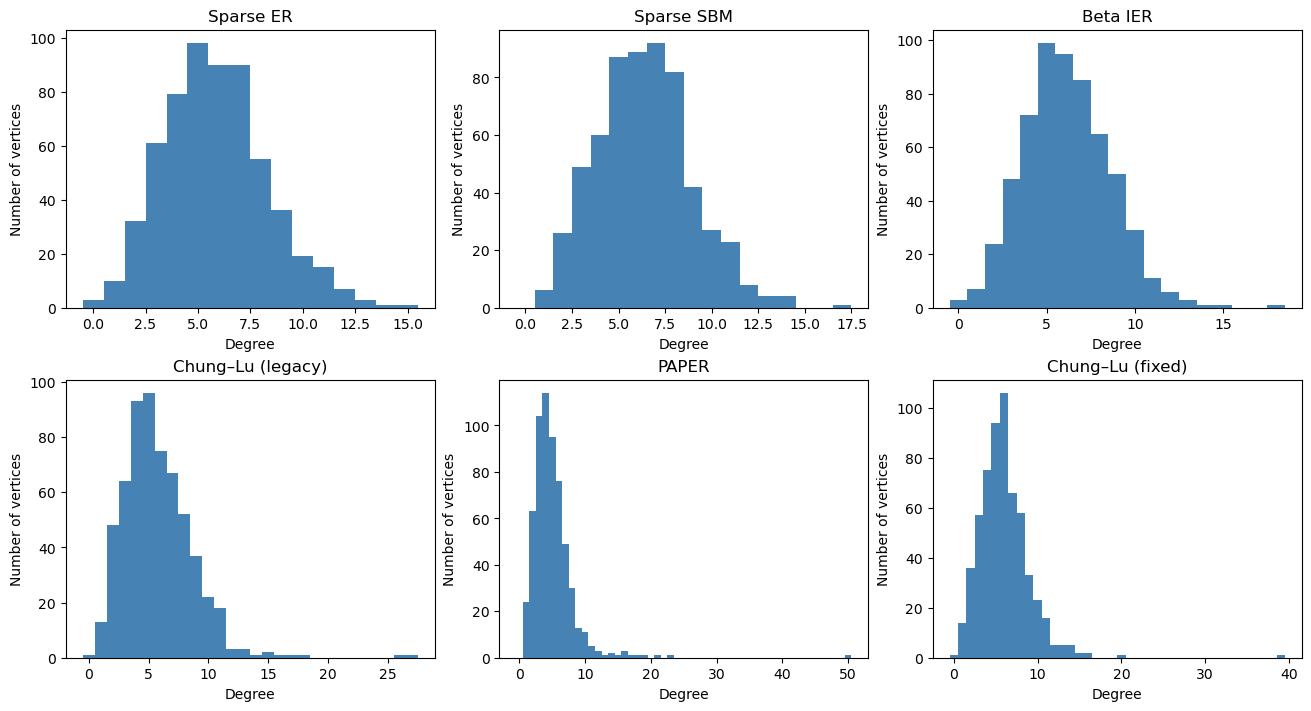

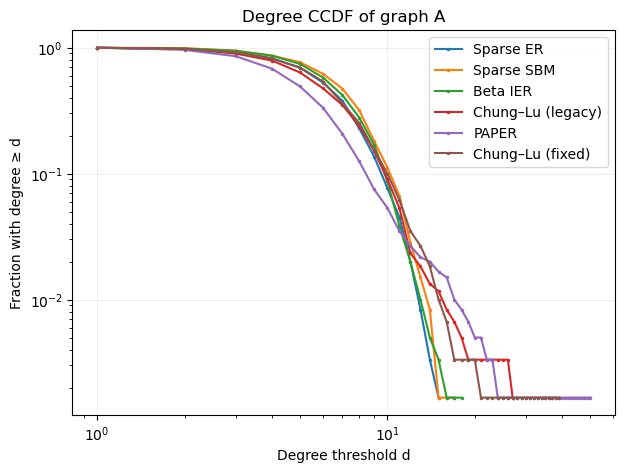

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, (key, label) in zip(axes.flat, MODELS.items()):
    degrees = pairs[key][0].sum(axis=1).astype(int)
    ax.hist(degrees, bins=np.arange(degrees.max() + 2) - 0.5, color="steelblue")
    ax.set(title=label, xlabel="Degree", ylabel="Number of vertices")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for key, label in MODELS.items():
    degrees = pairs[key][0].sum(axis=1)
    thresholds = np.arange(1, int(degrees.max()) + 1)
    ccdf = np.array([(degrees >= d).mean() for d in thresholds])
    ax.loglog(thresholds, ccdf, marker=".", markersize=3, label=label)
ax.set(xlabel="Degree threshold d", ylabel="Fraction with degree ≥ d", title="Degree CCDF of graph A")
ax.legend()
ax.grid(alpha=0.2)
plt.show()


## 4. Where the edges lie

These adjacency images use the original order of **graph A**. The SBM vertices are arranged by block. PAPER vertices retain their birth order. This ordering can reveal structure; it is not a property of the graph independent of vertex labels.

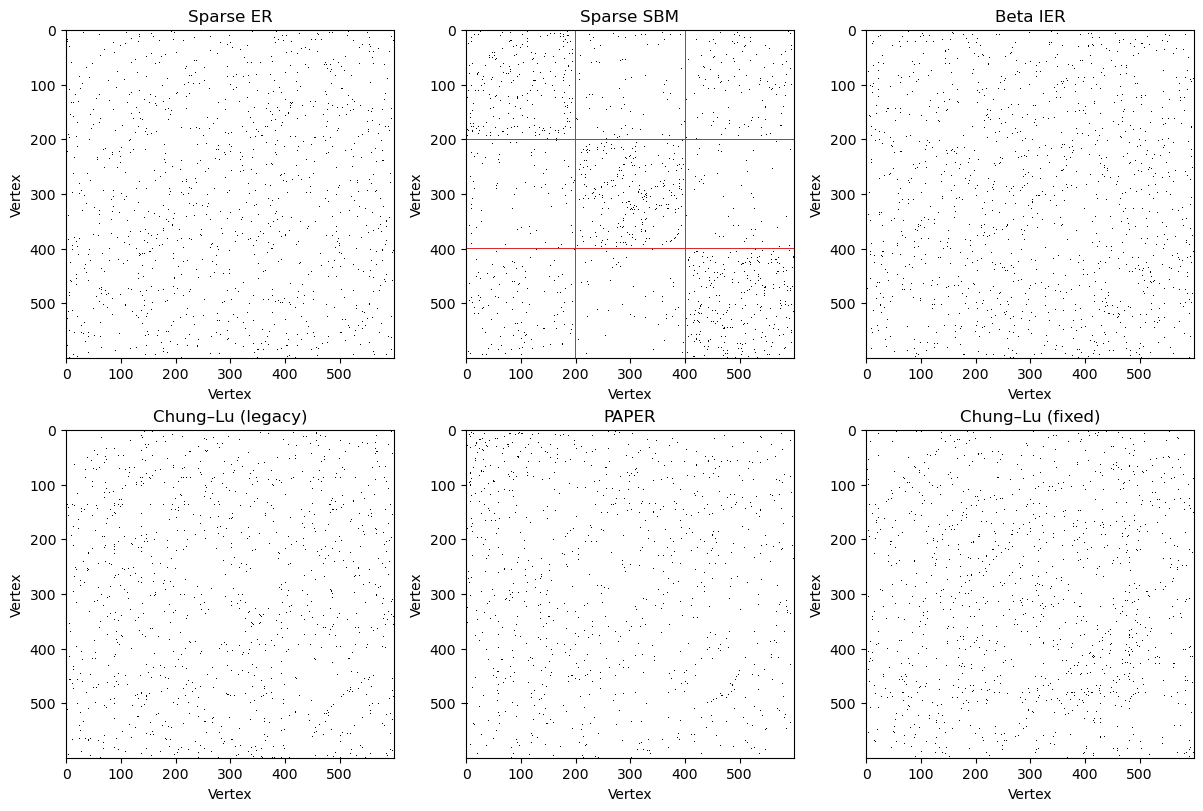

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for ax, (key, label) in zip(axes.flat, MODELS.items()):
    A = pairs[key][0]
    ax.imshow(A, cmap="Greys", vmin=0, vmax=1, interpolation="nearest", rasterized=True)
    ax.set(title=label, xlabel="Vertex", ylabel="Vertex")
    if key == "sparse_sbm":
        for boundary in (200, 400):
            ax.axvline(boundary - 0.5, color="tab:red", linewidth=0.7)
            ax.axhline(boundary - 0.5, color="tab:red", linewidth=0.7)
plt.show()


## 5. How similar are the two graphs in a pair?

For this **simulation-only diagnostic**, we use the known true correspondence to align `B` with `A`. The *preserved-edge fraction* is the fraction of A's edges also present in aligned B. The *edge Jaccard* divides shared edges by edges present in either graph. A *common neighbor* here is an incident edge present in both aligned graphs. These are not observable seed-set features in a real matching problem. The fraction of vertices with few common edges is only a rough structural diagnostic, **not** a bound on SGM accuracy.

`rho` is an edge-correlation input, not the preserved-edge fraction. In PAPER, the entire preferential-attachment tree is shared; `rho` affects only the ER component.

In [6]:
overlap_rows = []
for key, label in MODELS.items():
    A, B, truth = pairs[key]
    B_aligned = B[np.ix_(truth, truth)]
    common = (A > 0) & (B_aligned > 0)
    upper = np.triu_indices(len(A), k=1)
    a_edges = (A[upper] > 0)
    b_edges = (B_aligned[upper] > 0)
    shared = (a_edges & b_edges).sum()
    common_degree = common.sum(axis=1)
    overlap_rows.append({
        "model": label,
        "A_edges": int(a_edges.sum()),
        "B_edges": int(b_edges.sum()),
        "shared_edges": int(shared),
        "preserved_edge_fraction": shared / a_edges.sum(),
        "edge_Jaccard": shared / (a_edges | b_edges).sum(),
        "mean_common_degree": common_degree.mean(),
        "fraction_with_0_common_edges": np.mean(common_degree == 0),
        "fraction_with_at_most_1": np.mean(common_degree <= 1),
    })
display(pd.DataFrame(overlap_rows).set_index("model").round(3))


,A_edges,B_edges,shared_edges,preserved_edge_fraction,edge_Jaccard,mean_common_degree,fraction_with_0_common_edges,fraction_with_at_most_1
model,,,,,,,,
Sparse ER,1752,1727,1383,0.789,0.660,4.610,0.017,0.052
Sparse SBM,1918,1953,1534,0.800,0.656,5.113,0.003,0.033
Beta IER,1843,1785,1430,0.776,0.651,4.767,0.010,0.062
Chung–Lu (legacy),1731,1675,1220,0.705,0.558,4.067,0.015,0.118
PAPER,1501,1502,1177,0.784,0.645,3.923,0.000,0.108
Chung–Lu (fixed),1804,1806,1259,0.698,0.536,4.197,0.020,0.102


## 6. Variation from one generated pair to another

Generate a few independent pairs of each type and compare mean and maximum degree. The legacy Chung–Lu model draws new Pareto weights for each pair and sometimes globally rescales them. The fixed model uses the same weight quantiles on every pair, randomly assigned to vertices; its observed degrees still vary because edges are sampled. This cell only generates graphs; it does not run matching.

mean_degree              max_degree              
                          min median   max        min median    max
model                                                              
Beta IER                 5.66   6.05  6.22       14.0   15.0   17.0
Chung–Lu (fixed)         5.85   6.03  6.24       30.0   38.0   43.0
Chung–Lu (legacy)        3.48   5.14  6.29       20.0   28.0   48.0
PAPER                    4.72   5.04  5.18       32.0   46.5  102.0
Sparse ER                5.70   6.09  6.21       14.0   15.0   17.0
Sparse SBM               6.25   6.74  6.87       14.0   16.0   17.0

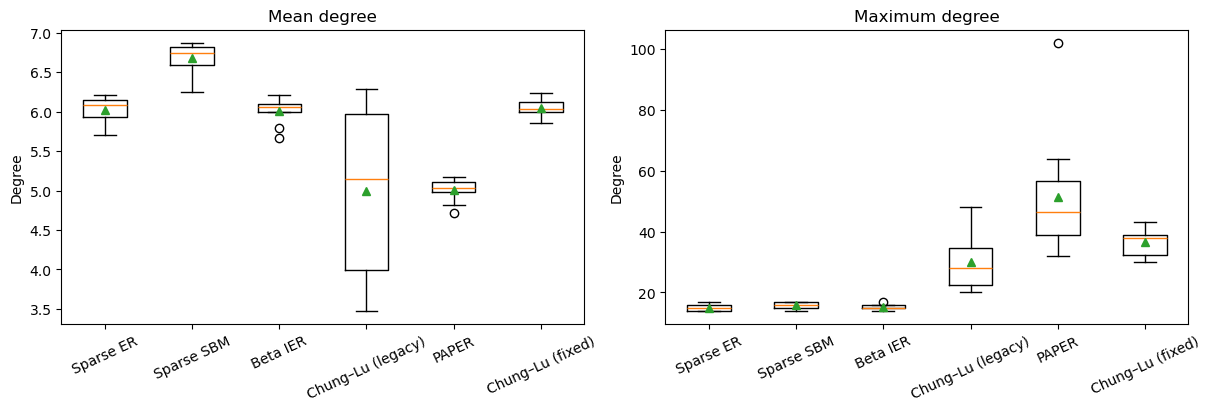

In [7]:
N_REPEATS = 10
repeated = []
for key, label in MODELS.items():
    config = preset_config(key)
    for repeat in range(N_REPEATS):
        seed = PAIR_SEED + 100 + repeat
        A, _, _ = generate_graph_pair(config, seed)
        degrees = A.sum(axis=1)
        repeated.append({
            "model": label,
            "pair_seed": seed,
            "mean_degree": degrees.mean(),
            "max_degree": degrees.max(),
        })
repeated = pd.DataFrame(repeated)
display(repeated.groupby("model")[["mean_degree", "max_degree"]].agg(["min", "median", "max"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, metric, title in zip(axes, ("mean_degree", "max_degree"), ("Mean degree", "Maximum degree")):
    data = [repeated.loc[repeated.model == label, metric].to_numpy() for label in MODELS.values()]
    ax.boxplot(data, tick_labels=list(MODELS.values()), showmeans=True)
    ax.set(title=title, ylabel="Degree")
    ax.tick_params(axis="x", rotation=25)
plt.show()


### Questions to consider after running

- Do ER and Beta IER look similar in degree distribution, as their current independent-probability construction predicts?
- Does SBM show a block pattern despite having a mean degree near the ER model?
- Is mean degree more stable across pairs with fixed-quantile Chung–Lu than with the legacy generator?
- How do the two Chung–Lu versions and PAPER differ in leaf counts, connectedness, and degree tails?
- Which models have many edges shared between A and B, and how much of PAPER's overlap comes from its shared tree?

These plots describe graph structure, not how well a particular seed set will match. They are a starting point for choosing and diagnosing later experiments.